# Customer Churn Prediction – Telco

**Objective:** Build a classification model to identify telecom customers likely to churn and determine the main drivers of churn.

**Dataset:** IBM Telco Customer Churn (public sample dataset, 7,043 customers, 21 features). Source: https://github.com/IBM/telco-customer-churn-on-icp4d

**Workflow:** data loading → cleaning → EDA → preprocessing → model comparison → evaluation → feature importance → model export.

## 1. Data loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Reads the CSV from the same folder as this notebook.
# If the file is not found (for example on Google Colab), it downloads the same public IBM file.
import os
LOCAL = "Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as text and needs to be converted to a numeric type.

## 2. Data cleaning

In [3]:
# TotalCharges has blank spaces for some customers. Convert to number; blanks become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["tenure","MonthlyCharges","TotalCharges"]])

Missing TotalCharges: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


All 11 records with a missing `TotalCharges` have `tenure = 0` (new customers who have not been billed yet), so the missing values were set to 0 instead of dropping rows or imputing an average. `customerID` was dropped and `Churn` was encoded as 1/0. 22 rows are identical after removing the ID; they were retained because they may be different customers on the same plan.

In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just a label, it has no predictive value
df = df.drop(columns=["customerID"])

# Convert target to numbers: Yes -> 1 (churned), No -> 0 (stayed)
df["Churn"] = df["Churn"].map({"Yes":1, "No":0})

print("Duplicate rows:", df.duplicated().sum())
print("Missing values left:", df.isna().sum().sum())

Duplicate rows: 22
Missing values left: 0


## 3. Exploratory data analysis

In [5]:
churn_rate = df["Churn"].mean()*100
print(f"Overall churn rate: {churn_rate:.1f}%")
df["Churn"].value_counts().rename({0:"Stayed",1:"Churned"})

Overall churn rate: 26.5%


Churn
Stayed     5174
Churned    1869
Name: count, dtype: int64

The overall churn rate is 26.5%, so the target is imbalanced. Accuracy alone can be misleading, so Precision, Recall, F1 and ROC-AUC are also reported.

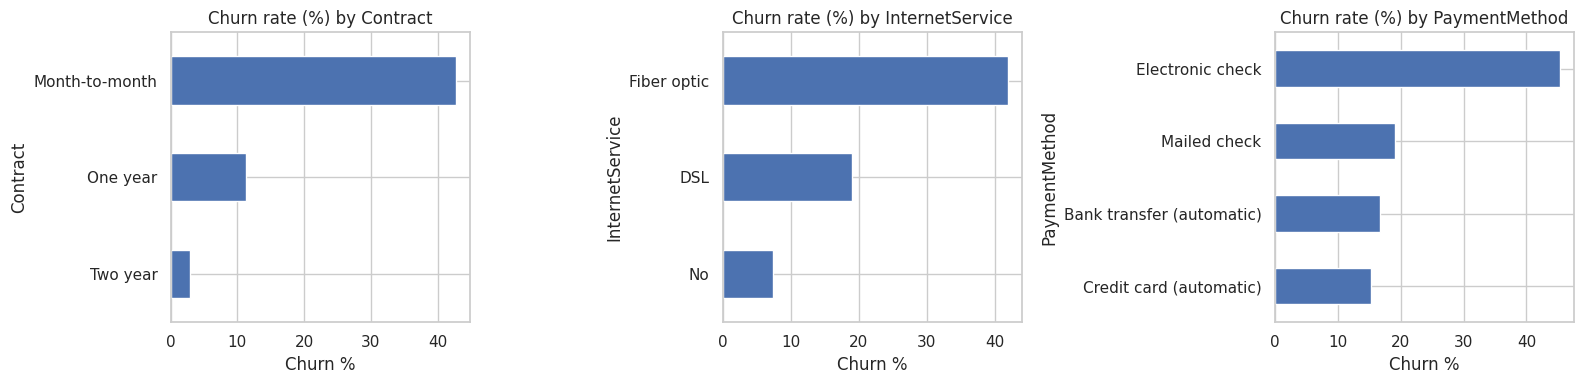

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))
for a, col in zip(ax, ["Contract","InternetService","PaymentMethod"]):
    (df.groupby(col)["Churn"].mean()*100).sort_values().plot(kind="barh", ax=a, color="#4C72B0")
    a.set_title(f"Churn rate (%) by {col}"); a.set_xlabel("Churn %")
plt.tight_layout(); plt.show()

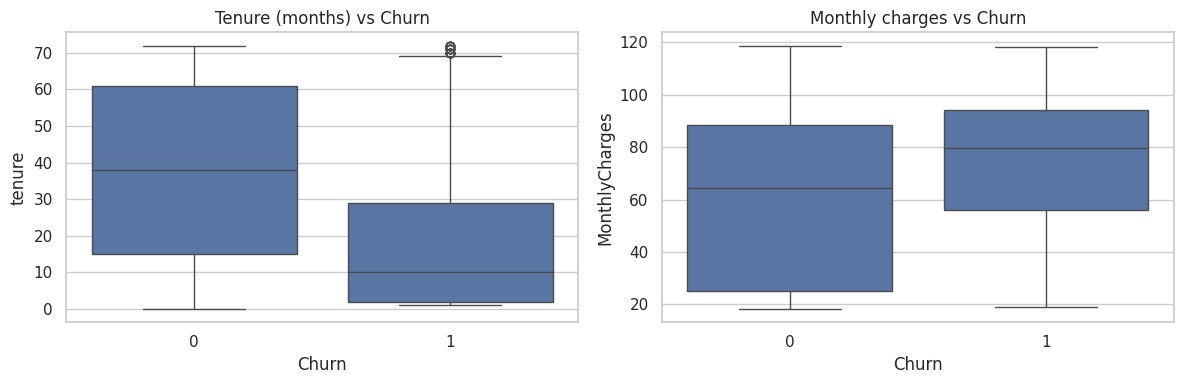

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=df, x="Churn", y="tenure", ax=ax[0]); ax[0].set_title("Tenure (months) vs Churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[1]); ax[1].set_title("Monthly charges vs Churn")
plt.tight_layout(); plt.show()

**Findings**
- Month-to-month contracts: 42.7% churn, compared with 11.3% (one year) and 2.8% (two year).
- Fibre optic internet: 41.9% churn, compared with 19.0% for DSL.
- Electronic check payments: 45.3% churn; other payment methods range from 15% to 19%.
- Median tenure is 10 months for churned customers and 38 months for retained customers; median monthly charges are 79.65 and 64.43 respectively.

## 4. Preprocessing

Numeric features (`tenure`, `MonthlyCharges`, `TotalCharges`) are standardised and categorical features are one-hot encoded. The data is split 80/20, stratified on the target (`random_state=42`), to preserve the churn ratio in both sets.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["Churn"])
y = df["Churn"]

num_cols = ["tenure","MonthlyCharges","TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(),3), round(y_test.mean(),3))

Train: (5634, 19)  Test: (1409, 19)
Churn rate train/test: 0.265 0.265


## 5. Model training and comparison

Three models are compared: Logistic Regression (baseline), Random Forest and XGBoost. Class imbalance is handled with class weights (`class_weight='balanced'`, `scale_pos_weight`). Each model is evaluated with 5-fold stratified cross-validation on the training set and on the hold-out test set.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

pos_weight = (y_train==0).sum() / (y_train==1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=pos_weight,
                             eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    pred  = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:,1]
    fitted[name] = pipe
    rows.append({"Model":name,
                 "CV ROC-AUC": round(cv_auc,3),
                 "Accuracy": round(accuracy_score(y_test,pred),3),
                 "Precision": round(precision_score(y_test,pred),3),
                 "Recall": round(recall_score(y_test,pred),3),
                 "F1": round(f1_score(y_test,pred),3),
                 "Test ROC-AUC": round(roc_auc_score(y_test,proba),3)})
results = pd.DataFrame(rows).set_index("Model")
results

,CV ROC-AUC,Accuracy,Precision,Recall,F1,Test ROC-AUC
Model,,,,,,
Logistic Regression,0.846,0.738,0.504,0.783,0.614,0.842
Random Forest,0.847,0.757,0.529,0.770,0.627,0.842
XGBoost,0.847,0.751,0.520,0.786,0.626,0.846


Precision is the share of predicted churners who actually churned; Recall is the share of actual churners that were identified; ROC-AUC measures how well the model separates churners from non-churners (0.5 = random). All three models perform very similarly (test ROC-AUC 0.842–0.846).

In [10]:
best_name = results["Test ROC-AUC"].idxmax()
print("Best model by Test ROC-AUC:", best_name)
best = fitted[best_name]

Best model by Test ROC-AUC: XGBoost


## 6. Evaluation of the best model

              precision    recall  f1-score   support

      Stayed       0.91      0.74      0.81      1035
     Churned       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



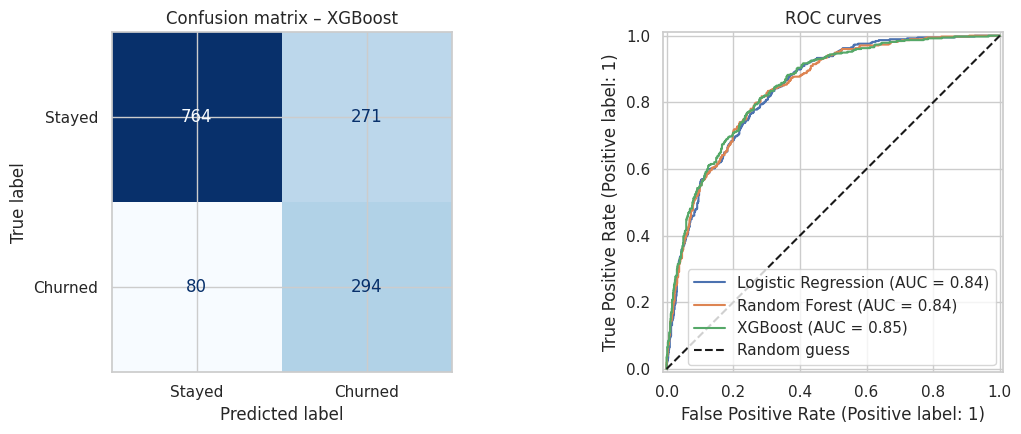

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report

pred  = best.predict(X_test)
proba = best.predict_proba(X_test)[:,1]
print(classification_report(y_test, pred, target_names=["Stayed","Churned"]))

fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed","Churned"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix – {best_name}")
for name, m in fitted.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax[1], name=name)
ax[1].plot([0,1],[0,1],"k--", label="Random guess"); ax[1].set_title("ROC curves"); ax[1].legend()
plt.tight_layout(); plt.show()

The confusion matrix shows correctly identified churners (bottom-right), missed churners (bottom-left) and false alarms (top-right).

## 7. Feature importance

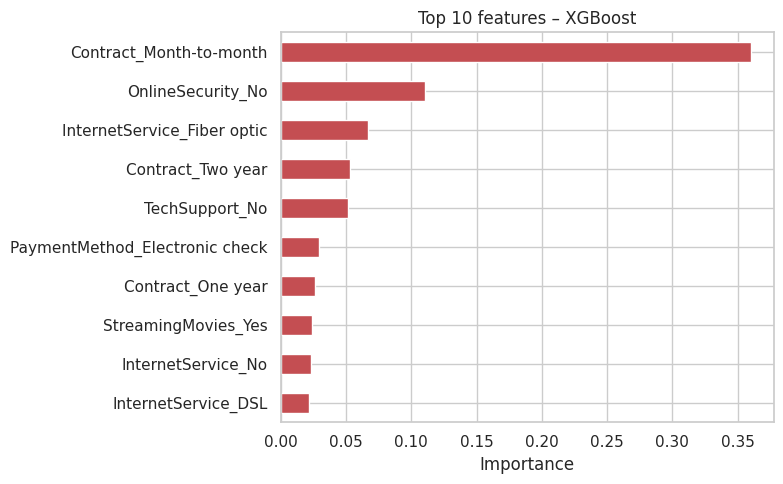

Contract_Month-to-month           0.359908
OnlineSecurity_No                 0.110744
InternetService_Fiber optic       0.066972
Contract_Two year                 0.053189
TechSupport_No                    0.051341
PaymentMethod_Electronic check    0.029269
Contract_One year                 0.026183
StreamingMovies_Yes               0.024172
InternetService_No                0.023085
InternetService_DSL               0.021882
dtype: float32

In [12]:
prep = best.named_steps["prep"]
model = best.named_steps["model"]
names = prep.get_feature_names_out()

if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=names)
else:
    imp = pd.Series(np.abs(model.coef_[0]), index=names)

imp.index = [n.replace("num__","").replace("cat__","") for n in imp.index]
top = imp.sort_values(ascending=False).head(10)
top.sort_values().plot(kind="barh", figsize=(8,5), color="#C44E52")
plt.title(f"Top 10 features – {best_name}"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()
top

**Recommendations (based on the observed patterns)**
1. Offer incentives to move month-to-month customers to one- or two-year contracts.
2. Focus retention outreach on customers in their first months of tenure.
3. Review pricing and service quality for fibre optic and high monthly-charge plans.
4. Encourage automatic payment methods over electronic check.

## 8. Save the model

In [13]:
import joblib
joblib.dump(best, "churn_model.joblib")
print("Saved churn_model.joblib")

# Example: score one new customer
sample = X_test.iloc[[0]]
print("Churn probability for first test customer:", round(best.predict_proba(sample)[0,1],3))

Saved churn_model.joblib
Churn probability for first test customer: 0.022


## Summary
- Cleaned 7,043 customer records and corrected `TotalCharges`.
- Compared Logistic Regression, Random Forest and XGBoost using 5-fold cross-validation and a hold-out test set.
- XGBoost scored highest (test ROC-AUC 0.846, recall 0.79), although the three models performed very similarly.
- The top model features were month-to-month contract, lack of online security and fibre optic internet; retention recommendations are outlined based on these and the EDA patterns.